# Credit Risk Prediction - Machine Learning Assignment (CO3117)

**Ho Chi Minh City University of Technology (HCMUT) - Faculty of Computer Science and Engineering**
Semester 1, academic year 2025-2026 - Advisor: Dr. Le Thanh Sach - Student: Duong Nguyen Tan Dat (2352222)

Task: predict whether a borrower will **default** on a loan (`loan_status = 1`) from the public
[Kaggle Credit Risk Dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset) (32,581 loans, 11 features).

| Part | Content |
|---|---|
| 1 | Setup: clone the code, install extra libraries, download the data |
| 2 | Exploratory data analysis (EDA) |
| 3 | Configurable traditional ML pipeline and ablation experiments |
| 4 | Hyper-parameter tuning, threshold tuning and test-set comparison of 8 classifiers |
| 5 | Saving extracted features (`.npy` / `.h5`) |
| 6 | Deep learning pipeline (entity-embedding MLP, TabNet) and comparison |
| 7 | Talented-engineering extension: Bayesian network with exact and approximate inference |
| 8 | Overall comparison and conclusions |

Source code: https://github.com/datduongabc/credit-risk-classification

**Runtime:** about 35 minutes on two modern CPU cores and up to about 2.5 hours on a free Colab runtime (no GPU
needed). *Runtime -> Run all* runs everything with no manual steps. No personal cloud storage is mounted. The data comes from a public URL.

## 1. Setup

In [1]:
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/datduongabc/credit-risk-classification.git"
REPO_DIR = "credit-risk-classification"

# Locate the project root: the repository itself when run locally, otherwise a fresh clone (Colab).
if Path("modules/creditrisk").is_dir():
    pass
elif Path("../modules/creditrisk").is_dir():
    os.chdir("..")
else:
    if not Path(REPO_DIR).is_dir():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)

ROOT = Path.cwd()
os.environ["CREDITRISK_ROOT"] = str(ROOT)
sys.path.insert(0, str(ROOT / "modules"))
print("Project root:", ROOT)

Project root: /home/asus/.treehouse/Assignment-643101/1/Assignment


In [2]:
# Libraries that Colab does not ship by default (no-op when already installed).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)

CompletedProcess(args=['/home/asus/.venvs/credit-risk/bin/python', '-m', 'pip', 'install', '-q', '-r', '/home/asus/.treehouse/Assignment-643101/1/Assignment/requirements.txt'], returncode=0)

In [3]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display

from creditrisk import config, data, eda, evaluation, experiments, pipeline, reporting, deep
from creditrisk.bayesnet import experiments as bnx

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
config.ensure_dirs()
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
import sklearn
# Parallel CV workers each hold distance matrices (k-NN) and forests in memory; capping the
# workers and sklearn's chunk size keeps peak RAM bounded on machines with many cores.
CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
N_JOBS = min(4, CORES)
sklearn.set_config(working_memory=256)
print(f"{CORES} CPU cores available, using {N_JOBS} parallel workers")
T_START = time.perf_counter()

2 CPU cores available, using 2 parallel workers


In [4]:
csv_path = data.download_dataset()  # public sources and checksum: config.DATASET_URLS, DATASET_SHA256
raw = data.load_raw(csv_path)
print(raw.shape)
raw.head()

Downloaded credit_risk_dataset.csv from https://github.com/datduongabc/credit-risk-classification/releases/download/data-v1/credit_risk_dataset.csv
(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Exploratory data analysis

A generic, automatic overview of every column (histograms, missing values, correlations, alerts) is
available in [`reports/eda_profile.html`](../reports/eda_profile.html), generated with
[ydata-profiling](https://github.com/ydataai/ydata-profiling) by `scripts/make_profile.py`. It is generated
outside the notebook because that library pins older numpy/pandas versions. Installing it inside Colab
could force a runtime restart and break *Run all*.

The sections below focus on the questions the generic profile does not answer: how each feature relates
to **default**, and what the findings imply for the pipeline.

### 2.1 Overview of the columns

In [5]:
ov = eda.overview(raw)
display(ov)
print("Exact duplicate rows:", raw.duplicated().sum())

,column,type,missing,missing_pct,unique,summary
0,person_age,numeric,0,0.000000,58,20 .. 144 (median 26)
1,person_income,numeric,0,0.000000,4295,4000 .. 6e+06 (median 55000)
2,person_home_ownership,categorical,0,0.000000,4,"RENT (16446), MORTGAGE (13444), OWN (2584), OT..."
3,person_emp_length,numeric,895,2.747000,36,0 .. 123 (median 4)
4,loan_intent,categorical,0,0.000000,6,"EDUCATION (6453), MEDICAL (6071), VENTURE (571..."
5,loan_grade,categorical,0,0.000000,7,"A (10777), B (10451), C (6458), D (3626)"
6,loan_amnt,numeric,0,0.000000,753,500 .. 35000 (median 8000)
7,loan_int_rate,numeric,3116,9.563856,348,5.42 .. 23.22 (median 10.99)
8,loan_status,categorical,0,0.000000,2,"0 (25473), 1 (7108)"
9,loan_percent_income,numeric,0,0.000000,77,0 .. 0.83 (median 0.15)


Exact duplicate rows: 165


In [6]:
num_summary = eda.numeric_summary(raw)
display(num_summary.round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
person_age,32581.0,27.73,6.35,20.00,21.00,23.00,26.00,30.00,50.00,144.00,2.58
person_income,32581.0,66074.85,61983.12,4000.00,14400.00,38500.00,55000.00,79200.00,225200.00,6000000.00,32.87
person_emp_length,31686.0,4.79,4.14,0.00,0.00,2.00,4.00,7.00,18.00,123.00,2.61
loan_amnt,32581.0,9589.37,6322.09,500.00,1000.00,5000.00,8000.00,12200.00,29800.00,35000.00,1.19
loan_int_rate,29465.0,11.01,3.24,5.42,5.42,7.90,10.99,13.47,18.62,23.22,0.21
loan_percent_income,32581.0,0.17,0.11,0.00,0.02,0.09,0.15,0.23,0.50,0.83,1.06
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,2.00,3.00,4.00,8.00,17.00,30.00,1.66


`person_age` reaches 144 and `person_emp_length` reaches 123 years, which are impossible values.
`person_income` is extremely right-skewed (skew > 30). Two columns have missing values:
`person_emp_length` (2.7%) and `loan_int_rate` (9.6%).

### 2.2 Target distribution

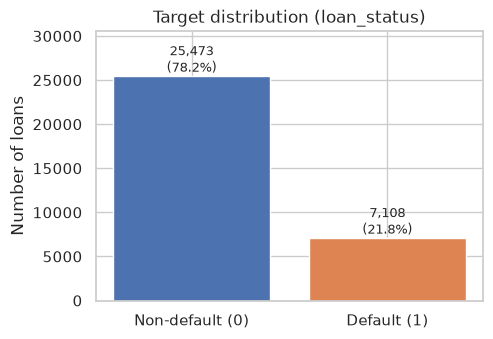

In [7]:
eda.plot_target(raw); plt.show()

About 21.8% of the loans default. The classes are imbalanced, so accuracy is misleading: always predicting
"non-default" already scores 78%. We therefore rank models by **PR-AUC** and tune the decision
threshold for **F2**, which weights recall on the default class twice as much as precision. Missing a
defaulter costs a lender much more than turning down a good applicant.

### 2.3 Numeric features

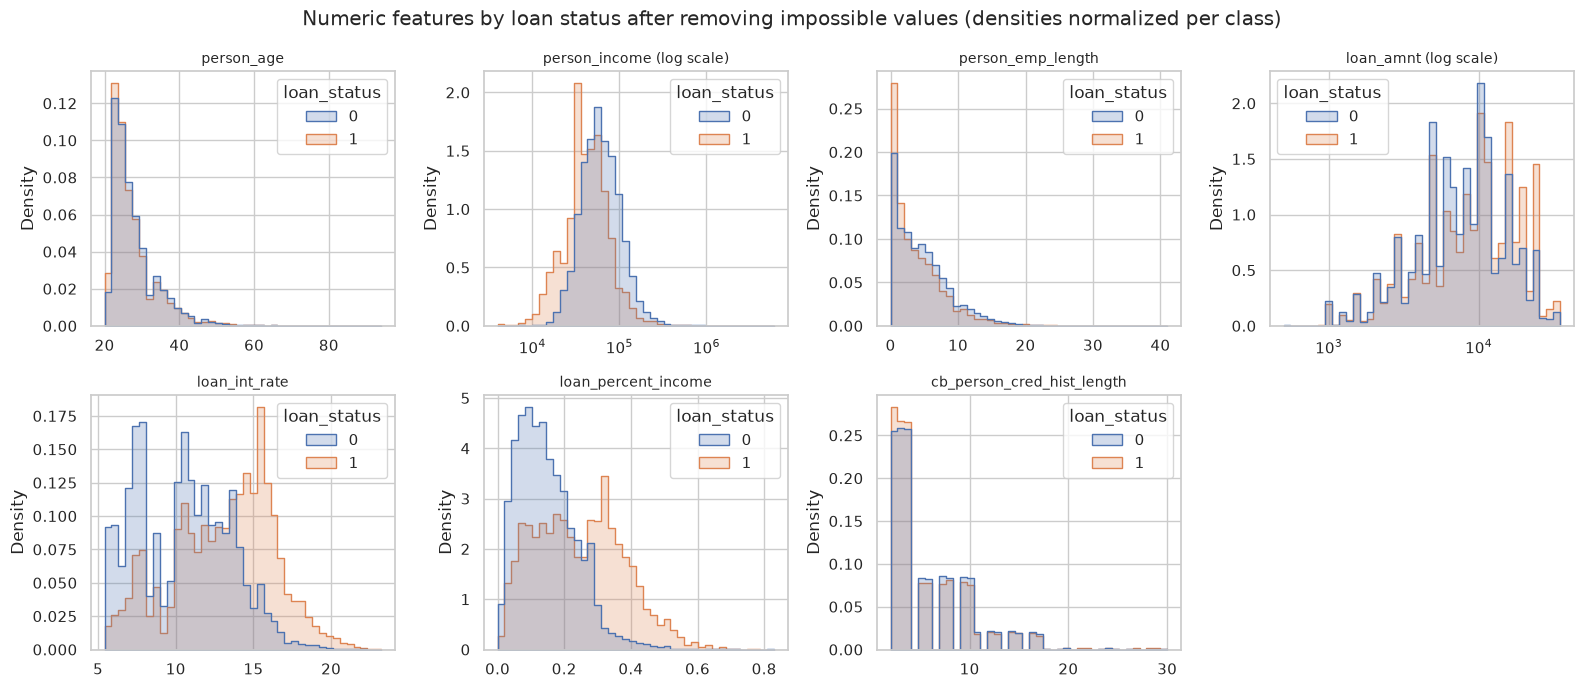

In [8]:
# Histograms use the rule-cleaned data (section 3.1) so that the five impossible ages and two impossible
# employment lengths do not stretch the axes; the box plots below show the raw values.
eda.plot_numeric_distributions(data.clean(raw)[0]); plt.show()

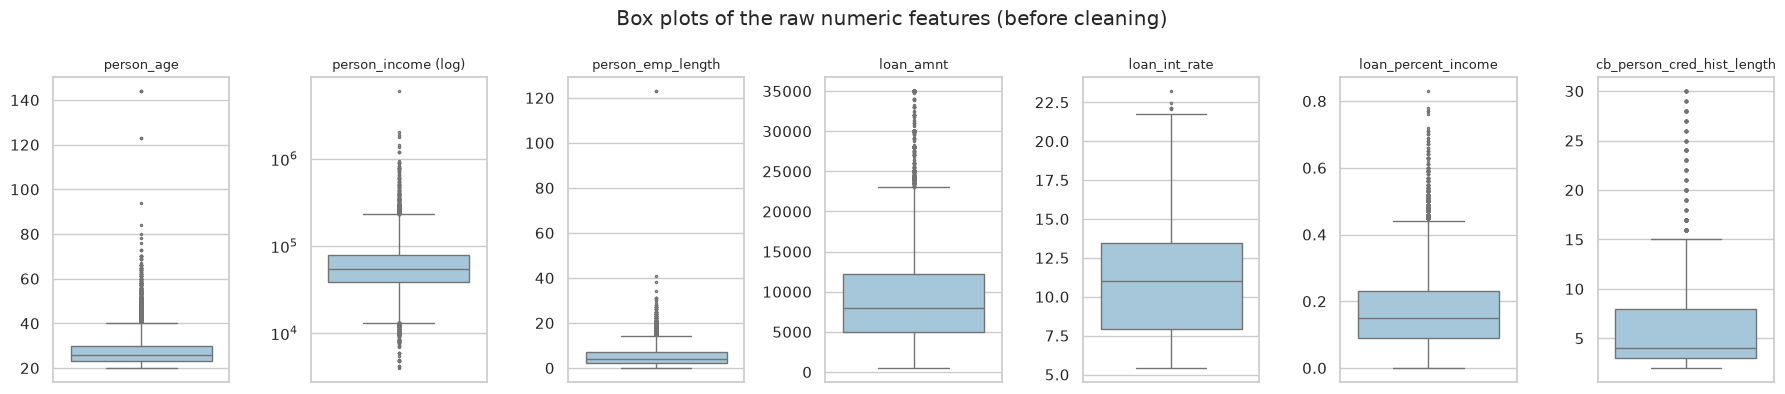

In [9]:
eda.plot_outliers(raw); plt.show()

### 2.4 Categorical features and default rate per category

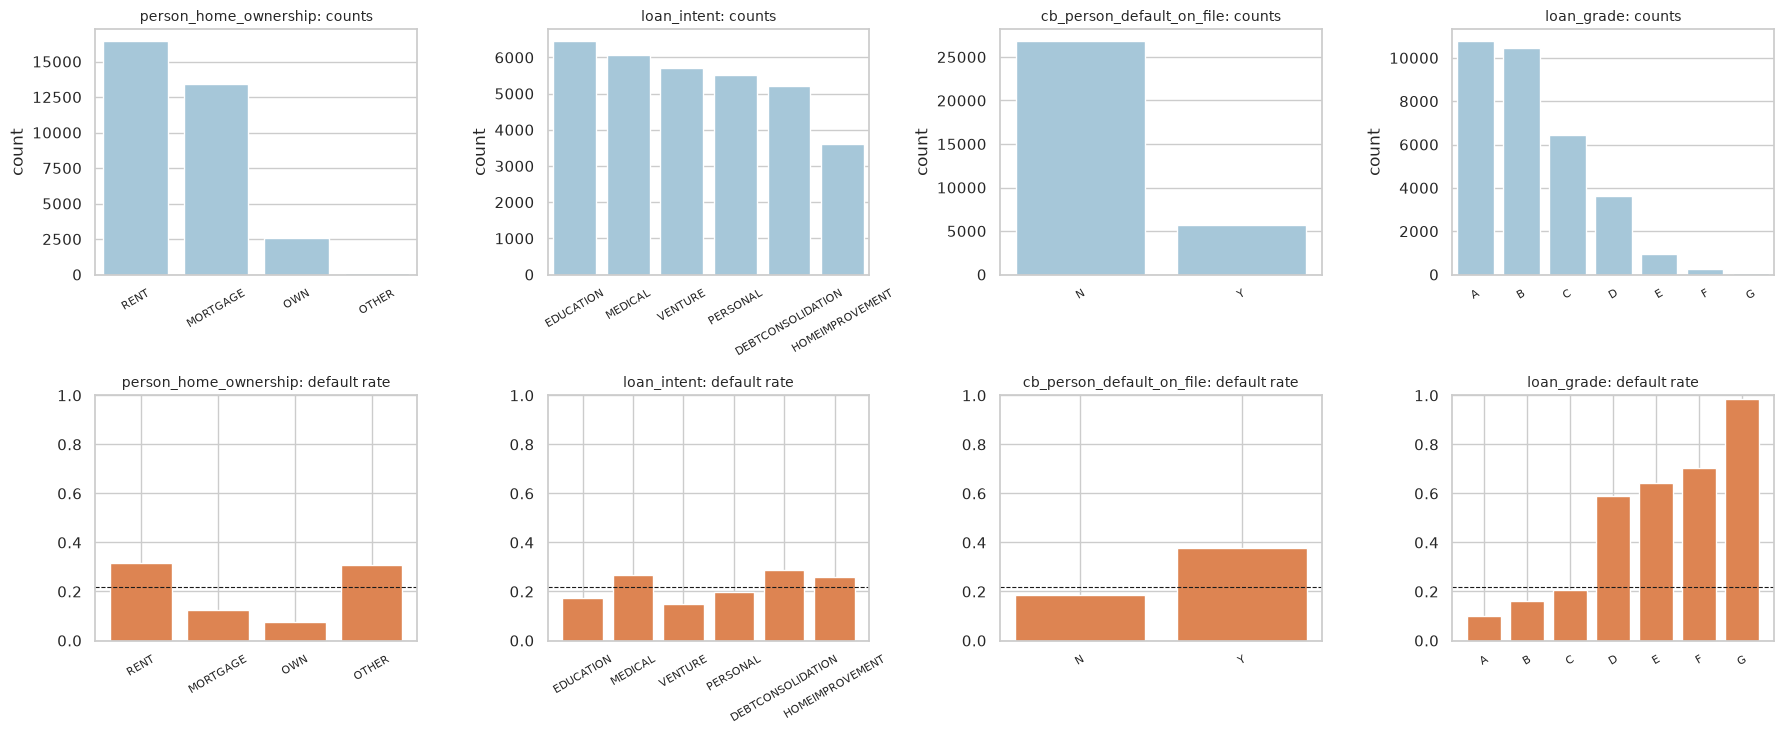

In [10]:
eda.plot_categorical(raw); plt.show()

### 2.5 Correlations

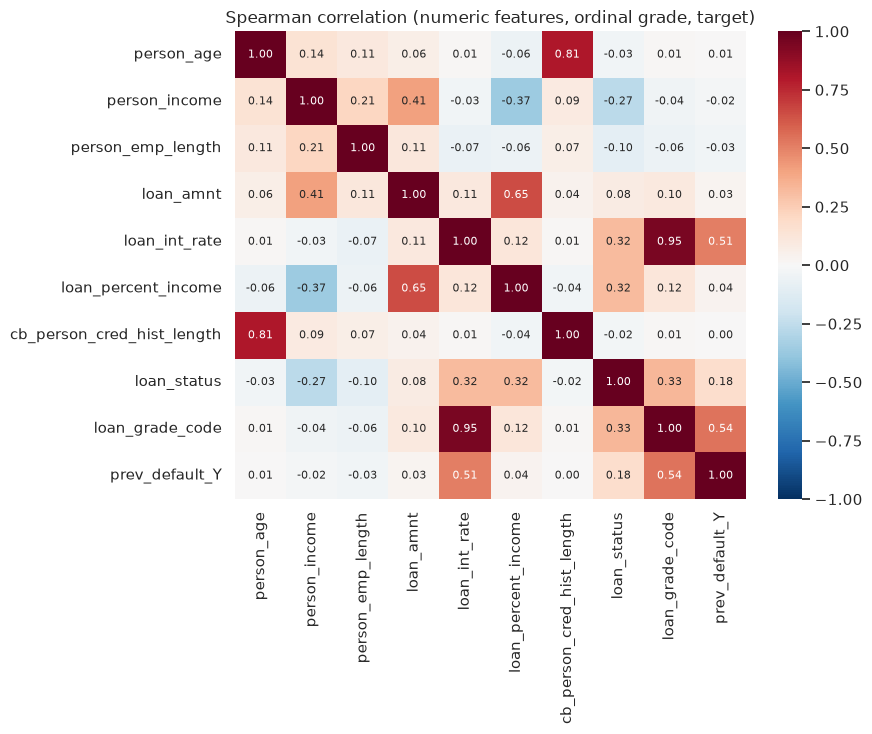

loan_grade_code               0.333
loan_int_rate                 0.320
loan_percent_income           0.316
person_income                -0.272
prev_default_Y                0.179
person_emp_length            -0.098
loan_amnt                     0.084
person_age                   -0.033
cb_person_cred_hist_length   -0.024
Name: loan_status, dtype: float64

In [11]:
fig, corr = eda.plot_correlations(raw); plt.show()
corr[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False).round(3)

### 2.6 Missing values

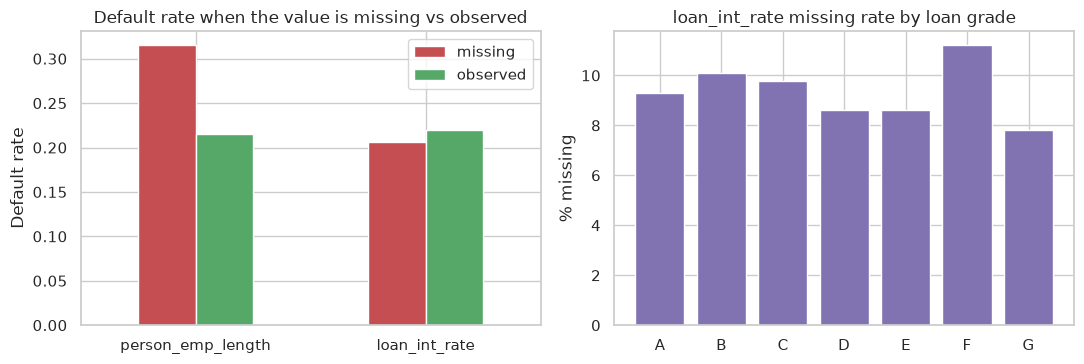

,missing,observed
person_emp_length,0.315,0.215
loan_int_rate,0.207,0.219


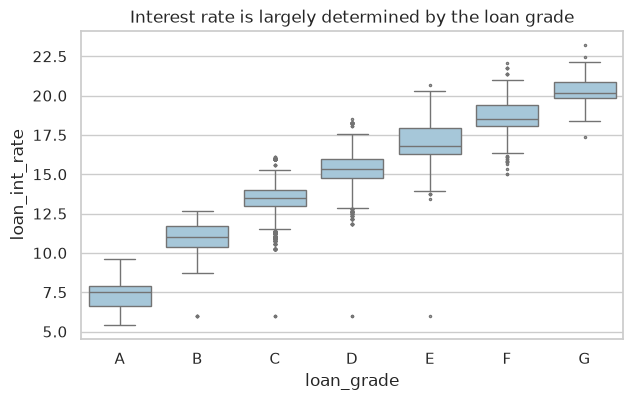

In [12]:
fig, miss_rates = eda.plot_missingness(raw); plt.show()
display(miss_rates.round(3))
eda.plot_rate_by_grade(raw); plt.show()

The two columns behave differently:
* A missing `loan_int_rate` says nothing about the outcome. Its default rate is about the same as for observed rates,
  and its missing share is flat across grades. It looks *missing completely at random*. The rate itself is almost a
  function of `loan_grade`, which motivates the **grade-wise median imputer**.
* A missing `person_emp_length` is informative: those applicants default about 50% more often than the rest. The
  missingness carries signal, which motivates the optional **missing-value indicator** columns tested in section 3.3.

### 2.7 Relevance of individual features

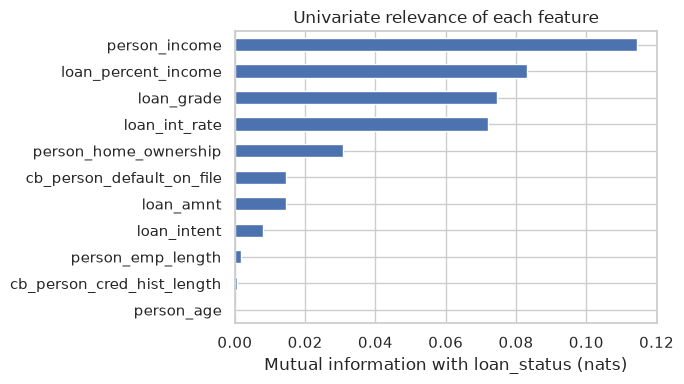

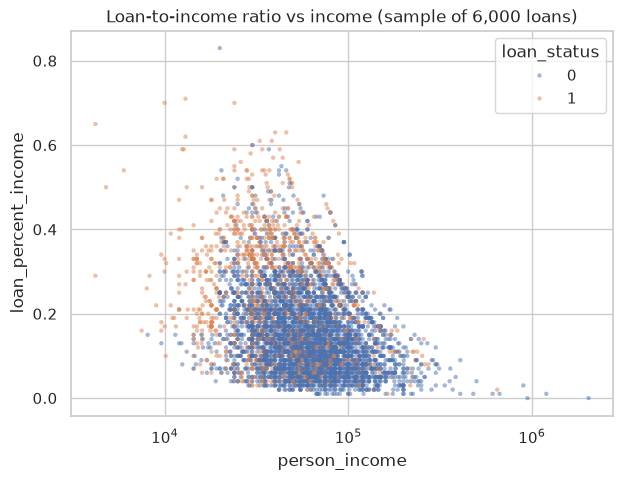

person_income                 0.1144
loan_percent_income           0.0831
loan_grade                    0.0745
loan_int_rate                 0.0720
person_home_ownership         0.0307
cb_person_default_on_file     0.0145
loan_amnt                     0.0144
loan_intent                   0.0081
person_emp_length             0.0018
cb_person_cred_hist_length    0.0005
person_age                    0.0000
dtype: float64

In [13]:
mi = eda.mutual_information(raw)
eda.plot_mutual_information(mi); plt.show()
eda.plot_burden_scatter(raw); plt.show()
mi.round(4)

## 3. Traditional machine learning pipeline

### 3.1 Cleaning and train/test split
Rule-based cleaning (no learned statistics, so it cannot leak test information) removes exact duplicates and
turns impossible values (age > 100, employment longer than age minus 14) into missing values. The
imputer then fills them. A stratified 80/20 split holds out a test set that is used **only** for the final
comparisons.

In [14]:
X_train, X_test, y_train, y_test, cleaning = data.load_splits()
print(cleaning.as_dict())
print("train:", X_train.shape, "default rate %.4f" % y_train.mean())
print("test: ", X_test.shape, "default rate %.4f" % y_test.mean())

{'n_raw': 32581, 'n_duplicates': 165, 'n_invalid_age': 5, 'n_invalid_emp_length': 2, 'n_clean': 32416}
train: (25932, 11) default rate 0.2187
test:  (6484, 11) default rate 0.2187


#### Is "impossible value -> missing" the right choice?
There are several ways to handle an age of 144: keep it, drop the row, replace it by the mean or median, cap it
at a plausible value, or mark it missing and let the pipeline's imputer fill it. The comparison below scores
every option with 5-fold CV on the same validation rows, for a tree ensemble and a linear model.

In [15]:
impossible = experiments.run_impossible_values({
    "Hist. Gradient Boosting": pipeline.build_pipeline(experiments.PREP_TREE.with_(model="hist_gb")),
    "Logistic Regression": pipeline.build_pipeline(experiments.PREP_SCALED.with_(model="logreg")),
}, verbose=False)
display(impossible.pivot(index="strategy", columns="model", values="pr_auc").round(5))
print("typical fold standard deviation: %.4f" % impossible["pr_auc_std"].mean())

model,Hist. Gradient Boosting,Logistic Regression
strategy,,
cap to plausible value,0.89656,0.75360
drop rows,0.89681,0.75360
keep as is,0.89660,0.75358
"missing, then pipeline imputer",0.89769,0.75356
replace by mean,0.89769,0.75360
replace by median,0.89769,0.75356


typical fold standard deviation: 0.0052


Only 7 training rows (and no test row) are affected, so every strategy scores within a fraction of the fold
standard deviation of the others. Performance cannot separate them, so the choice is made on methodology.
"Missing, then imputer" keeps the row's ten valid columns. It learns the fill value inside each training fold,
which avoids leakage. It can use any configured imputer (MICE can infer age from credit-history length). And
it is the only option that also works for a new applicant at prediction time, where a row cannot be dropped.

### 3.2 A configurable pipeline
Every step is chosen through a `PipelineConfig`:

| Step | Options |
|---|---|
| Missing values | mean, median, grade-wise median, KNN, iterative (MICE); optional missing indicators |
| Feature engineering | optional log income, log amount, income per credit-history year, rate x burden |
| Outliers | none, IQR clipping (winsorizing), log transform |
| Encoding | one-hot for nominal features; loan grade ordinal or one-hot |
| Scaling | none, StandardScaler, MinMaxScaler(`feature_range`), RobustScaler |
| Feature selection / reduction | SelectKBest (mutual information), PCA with a retained-variance level |
| Class imbalance | none, class weights, SMOTE, random under-sampling |
| Model | Logistic Regression, Linear SVM, RBF SVM, k-NN, Gaussian NB, Decision Tree, Random Forest, Hist. Gradient Boosting |

All learned steps sit inside one `imblearn.Pipeline`, so cross-validation refits them on each training fold.

In [16]:
example = pipeline.PipelineConfig(imputer="group_median", feature_engineering=True, outlier="clip_iqr",
                                  grade_encoding="onehot", scaler="minmax", feature_range=(-1, 1),
                                  pca_variance=0.95, resampler="smote", model="svm")
example_pipe = pipeline.build_pipeline(example)
display(example_pipe)

,steps,"[('group_impute', ...), ('engineer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,column,'loan_int_rate'
,group,'loan_grade'
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function _ad...x782141f827a0>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",<function _ra...x782141f83b00>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


### 3.3 Ablation experiments (5-fold stratified CV on the training set)
Each suite changes one step and keeps the rest at a reference configuration.

In [17]:
suites = {}
for name, variants in experiments.SUITES.items():
    t0 = time.perf_counter()
    suites[name] = experiments.run_suite(name, variants(), X_train, y_train, n_jobs=N_JOBS, verbose=False)
    print(f"{name:15s} {len(suites[name]):2d} configurations in {time.perf_counter() - t0:.0f}s")

imputation      12 configurations in 105s


scaling         14 configurations in 162s


outlier_fe      12 configurations in 84s


encoding         6 configurations in 27s


dimensionality  24 configurations in 208s


imbalance       12 configurations in 57s


,model,imputer,indicator,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,mean,False,0.6984,0.0046,0.8642,0.7061,0.7799,0.5122
1,Logistic Regression,median,False,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
2,Logistic Regression,group_median,False,0.6989,0.0044,0.8643,0.7075,0.7806,0.5149
3,Logistic Regression,knn,False,0.6986,0.0045,0.8642,0.7059,0.7799,0.5117
4,Logistic Regression,iterative,False,0.6985,0.0046,0.8642,0.7061,0.7799,0.5122
5,Logistic Regression,median,True,0.6999,0.0052,0.8652,0.7079,0.7813,0.5145
6,Random Forest,mean,False,0.8835,0.0016,0.9324,0.7675,0.7381,0.9127
7,Random Forest,median,False,0.8827,0.0016,0.9313,0.7685,0.7392,0.9136
8,Random Forest,group_median,False,0.8838,0.0017,0.9325,0.7691,0.7397,0.9144
9,Random Forest,knn,False,0.8839,0.0016,0.9321,0.7682,0.7380,0.9186


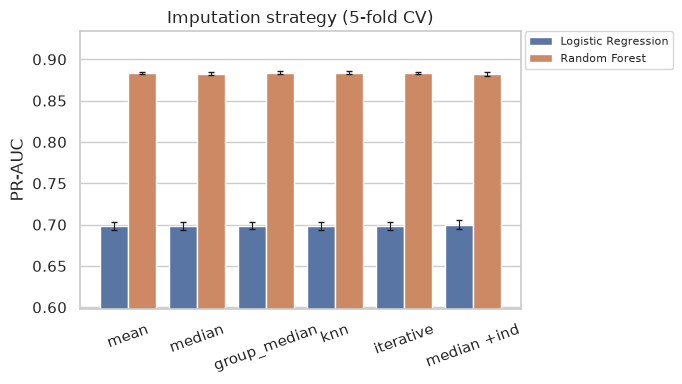

In [18]:
COLS = ["pr_auc", "pr_auc_std", "roc_auc", "f2", "recall", "precision"]
def show(name, keys):
    df = suites[name][keys + COLS]
    display(df.round(4))
    return df

show("imputation", ["model", "imputer", "indicator"])
reporting.plot_suite(suites["imputation"].assign(variant=lambda d: d.imputer + np.where(d.indicator, " +ind", "")),
                     x="variant", title="Imputation strategy (5-fold CV)", name="suite_imputation"); plt.show()

,model,scaler,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,none,0.6650,0.0098,0.8449,0.6884,0.7792,0.4696
1,Logistic Regression,standard,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
2,Logistic Regression,"minmax [0,1]",0.6996,0.0048,0.8642,0.7066,0.7810,0.5120
3,Logistic Regression,"minmax [-1,1]",0.6990,0.0049,0.8642,0.7069,0.7808,0.5129
4,Logistic Regression,robust,0.6986,0.0046,0.8642,0.7060,0.7798,0.5124
5,k-NN,none,0.6153,0.0109,0.8203,0.4926,0.4594,0.6949
6,k-NN,standard,0.7775,0.0072,0.8827,0.6114,0.5664,0.8964
7,k-NN,"minmax [0,1]",0.7720,0.0072,0.8778,0.6098,0.5646,0.8972
8,k-NN,"minmax [-1,1]",0.7723,0.0071,0.8779,0.6113,0.5662,0.8975
9,k-NN,robust,0.7708,0.0070,0.8820,0.5766,0.5288,0.9026


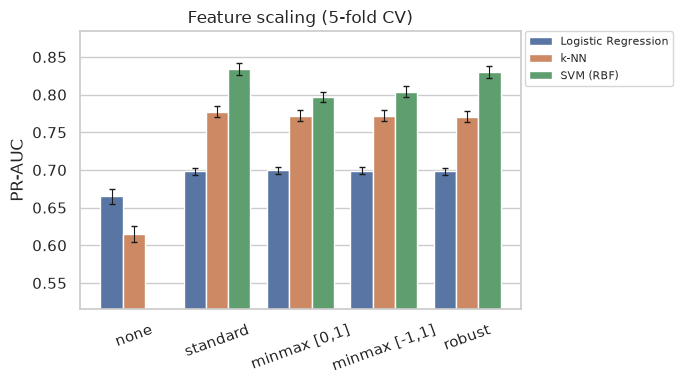

In [19]:
show("scaling", ["model", "scaler"])
reporting.plot_suite(suites["scaling"], x="scaler", title="Feature scaling (5-fold CV)", name="suite_scaling"); plt.show()

,model,outlier,feat_eng,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,none,False,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
1,Logistic Regression,none,True,0.7122,0.0037,0.8761,0.7221,0.7983,0.5226
2,Logistic Regression,clip_iqr,False,0.7021,0.0049,0.8656,0.7082,0.7833,0.5120
3,Logistic Regression,clip_iqr,True,0.7220,0.0053,0.8771,0.7273,0.8022,0.5297
4,Logistic Regression,log,False,0.7105,0.0040,0.8717,0.7133,0.7877,0.5179
5,Logistic Regression,log,True,0.7160,0.0035,0.8765,0.7227,0.7958,0.5285
6,Random Forest,none,False,0.8827,0.0016,0.9313,0.7685,0.7392,0.9136
7,Random Forest,none,True,0.8852,0.0011,0.9332,0.7721,0.7466,0.8942
8,Random Forest,clip_iqr,False,0.8834,0.0020,0.9319,0.7690,0.7396,0.9146
9,Random Forest,clip_iqr,True,0.8854,0.0011,0.9333,0.7718,0.7461,0.8951


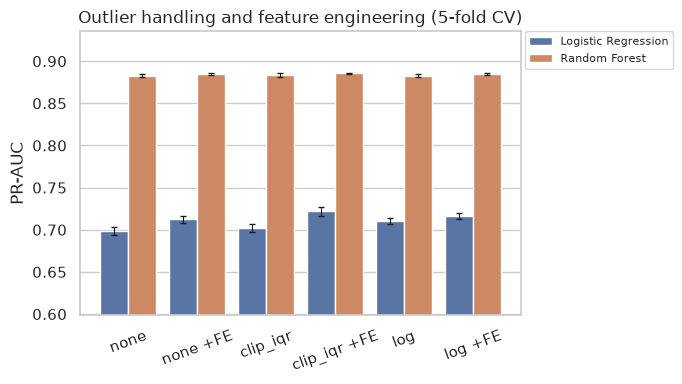

In [20]:
show("outlier_fe", ["model", "outlier", "feat_eng"])
reporting.plot_suite(suites["outlier_fe"].assign(variant=lambda d: d.outlier + np.where(d.feat_eng, " +FE", "")),
                     x="variant", title="Outlier handling and feature engineering (5-fold CV)", name="suite_outlier_fe"); plt.show()

,model,grade_encoding,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,ordinal,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
1,Logistic Regression,onehot,0.7165,0.0061,0.8708,0.7181,0.7791,0.5470
2,k-NN,ordinal,0.7775,0.0072,0.8827,0.6114,0.5664,0.8964
3,k-NN,onehot,0.7748,0.0083,0.8787,0.6179,0.5743,0.8871
4,Random Forest,ordinal,0.8827,0.0016,0.9313,0.7685,0.7392,0.9136
5,Random Forest,onehot,0.8819,0.0018,0.9309,0.7667,0.7392,0.9010


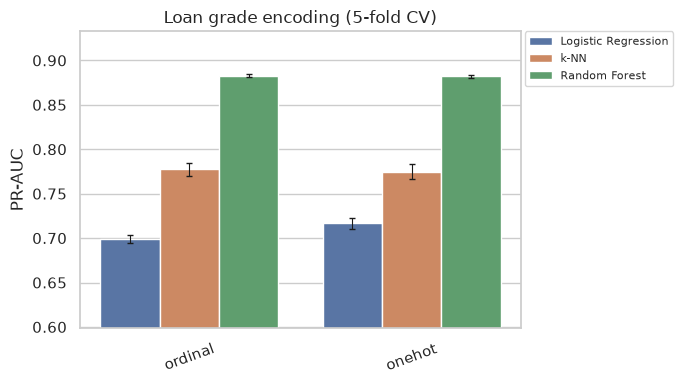

In [21]:
show("encoding", ["model", "grade_encoding"])
reporting.plot_suite(suites["encoding"], x="grade_encoding", title="Loan grade encoding (5-fold CV)", name="suite_encoding"); plt.show()

,model,reduction,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,none,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
1,Logistic Regression,PCA 80%,0.6485,0.0095,0.8391,0.6867,0.7755,0.4711
2,Logistic Regression,PCA 90%,0.6571,0.0048,0.8447,0.6869,0.7685,0.4824
3,Logistic Regression,PCA 95%,0.6755,0.0086,0.8517,0.6957,0.7764,0.4915
4,Logistic Regression,PCA 99%,0.6983,0.0046,0.8642,0.7064,0.7805,0.5123
5,Logistic Regression,SelectKBest k=5,0.6693,0.0055,0.8475,0.6984,0.7798,0.4927
6,Logistic Regression,SelectKBest k=10,0.6837,0.0053,0.8572,0.7007,0.7745,0.5075
7,Logistic Regression,SelectKBest k=15,0.6920,0.0059,0.8614,0.7009,0.7739,0.5090
8,k-NN,none,0.7775,0.0072,0.8827,0.6114,0.5664,0.8964
9,k-NN,PCA 80%,0.7251,0.0217,0.8648,0.5695,0.5317,0.7960


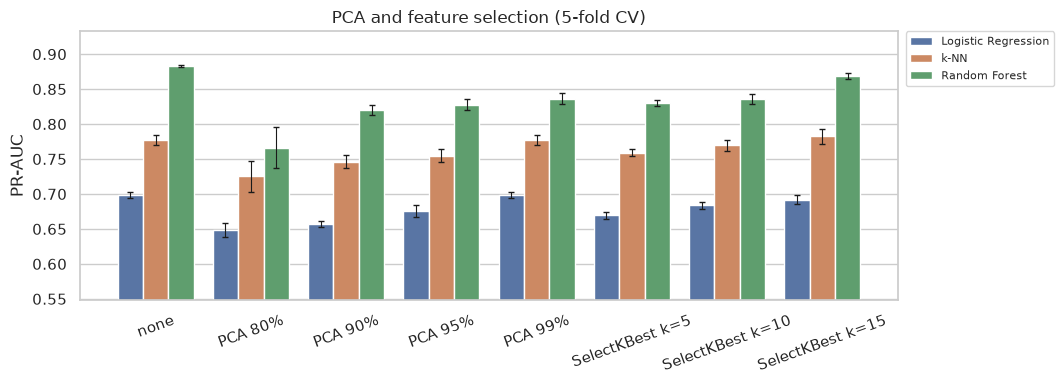

In [22]:
show("dimensionality", ["model", "reduction"])
reporting.plot_suite(suites["dimensionality"], x="reduction", title="PCA and feature selection (5-fold CV)", name="suite_dimensionality"); plt.show()

,model,imbalance,pr_auc,pr_auc_std,roc_auc,f2,recall,precision
0,Logistic Regression,none,0.7026,0.0039,0.8637,0.5390,0.5050,0.7381
1,Logistic Regression,class_weight,0.6985,0.0045,0.8642,0.7063,0.7801,0.5125
2,Logistic Regression,smote,0.6983,0.0050,0.8638,0.7041,0.7750,0.5155
3,Logistic Regression,undersample,0.6983,0.0038,0.8641,0.7080,0.7822,0.5133
4,Random Forest,none,0.8843,0.0017,0.9314,0.7554,0.7152,0.9743
5,Random Forest,class_weight,0.8827,0.0016,0.9313,0.7685,0.7392,0.9136
6,Random Forest,smote,0.8792,0.0023,0.9280,0.7568,0.7182,0.9641
7,Random Forest,undersample,0.8766,0.0016,0.9291,0.7809,0.7939,0.7334
8,Hist. Gradient Boosting,none,0.8982,0.0016,0.9440,0.7657,0.7265,0.9761
9,Hist. Gradient Boosting,class_weight,0.8986,0.0029,0.9442,0.7923,0.7819,0.8370


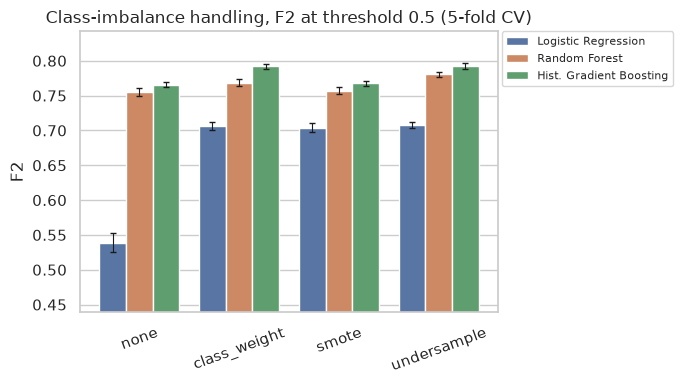

In [23]:
show("imbalance", ["model", "imbalance"])
reporting.plot_suite(suites["imbalance"], x="imbalance", metric="f2", title="Class-imbalance handling, F2 at threshold 0.5 (5-fold CV)", name="suite_imbalance"); plt.show()

**Take-aways used for the final configurations**:
- Scaling is essential for distance- and margin-based models (k-NN, SVM).
- The engineered ratio features, IQR clipping and a one-hot loan grade help the linear models.
- The imputation method barely matters at these missing-value levels.
- PCA never helps: it is neutral at 99% retained variance and harmful below, because the ~20 encoded features are not redundant.
- Class weights raise F2 at the default threshold without hurting PR-AUC.

## 4. Model comparison
### 4.1 Hyper-parameter search (5-fold CV, refit on PR-AUC)

In [24]:
tuning, searches = experiments.tune_models(X_train, y_train, n_jobs=N_JOBS)
display(tuning[["model", "best_params", "cv_pr_auc", "cv_pr_auc_std", "cv_roc_auc", "cv_f2", "cv_recall", "search_time"]].round(4))

[tune] Logistic Regression      PR-AUC=0.7538  best={'model__C': 10, 'model__class_weight': None}  (4s)


[tune] Linear SVM               PR-AUC=0.7473  best={'model__C': 1, 'model__class_weight': None}  (2s)


[tune] SVM (RBF)                PR-AUC=0.8501  best={'model__C': 10, 'model__gamma': 'scale'}  (164s)


[tune] k-NN                     PR-AUC=0.8134  best={'model__n_neighbors': 15, 'model__weights': 'distance'}  (12s)


[tune] Gaussian Naive Bayes     PR-AUC=0.6229  best={'model__var_smoothing': 0.001}  (1s)


[tune] Decision Tree            PR-AUC=0.8598  best={'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 20}  (6s)


[tune] Random Forest            PR-AUC=0.8902  best={'model__class_weight': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 3}  (198s)


[tune] Hist. Gradient Boosting  PR-AUC=0.8988  best={'model__class_weight': None, 'model__learning_rate': 0.05, 'model__max_iter': 300, 'model__max_leaf_nodes': 31}  (22s)


,model,best_params,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_f2,cv_recall,search_time
0,Logistic Regression,"{'model__C': 10, 'model__class_weight': None}",0.7538,0.0072,0.8827,0.6247,0.5967,3.5892
1,Linear SVM,"{'model__C': 1, 'model__class_weight': None}",0.7473,0.0071,0.8801,0.6152,0.5861,2.3983
2,SVM (RBF),"{'model__C': 10, 'model__gamma': 'scale'}",0.8501,0.0045,0.9115,0.7634,0.7662,164.4599
3,k-NN,"{'model__n_neighbors': 15, 'model__weights': '...",0.8134,0.0058,0.8934,0.6459,0.6066,12.4597
4,Gaussian Naive Bayes,{'model__var_smoothing': 0.001},0.6229,0.0120,0.8552,0.6077,0.5995,0.9364
5,Decision Tree,"{'model__class_weight': None, 'model__max_dept...",0.8598,0.0040,0.9151,0.7438,0.7050,5.5977
6,Random Forest,"{'model__class_weight': None, 'model__max_feat...",0.8902,0.0025,0.9341,0.7526,0.7117,198.3699
7,Hist. Gradient Boosting,"{'model__class_weight': None, 'model__learning...",0.8988,0.0026,0.9441,0.7656,0.7265,22.0601


### 4.2 Decision threshold tuned for F2
`TunedThresholdClassifierCV` picks the threshold that maximizes F2 with internal cross-validation on the
training set. The test set never influences it.

In [25]:
best = {k: gs.best_estimator_ for k, gs in searches.items()}
thresholded = {k: experiments.tune_threshold(est, X_train, y_train, n_jobs=N_JOBS) for k, est in best.items()}
test_results = experiments.evaluate_on_test(best, X_test, y_test, thresholded)
test_results.to_csv(config.RESULTS_DIR / "test_traditional.csv", index=False)
display(test_results[["model", "pr_auc", "roc_auc", "accuracy", "f1", "threshold", "f2_tuned", "recall_tuned", "precision_tuned"]]
        .sort_values("pr_auc", ascending=False).round(4))

,model,pr_auc,roc_auc,accuracy,f1,threshold,f2_tuned,recall_tuned,precision_tuned
7,Hist. Gradient Boosting,0.9045,0.9459,0.9378,0.8368,0.1515,0.8132,0.8512,0.6901
6,Random Forest,0.8934,0.9361,0.9366,0.8330,0.2222,0.8021,0.8068,0.7841
5,Decision Tree,0.8623,0.9180,0.9304,0.8164,0.1414,0.7670,0.7856,0.7006
2,SVM (RBF),0.8561,0.9147,0.8985,0.7673,-0.4900,0.7703,0.8117,0.6398
3,k-NN,0.8163,0.8925,0.8962,0.7229,0.2424,0.7501,0.7906,0.6228
0,Logistic Regression,0.7512,0.8797,0.8703,0.6685,0.2224,0.7360,0.7955,0.5665
1,Linear SVM,0.7443,0.8774,0.8689,0.6624,-0.4521,0.7339,0.7962,0.5589
4,Gaussian Naive Bayes,0.6244,0.8503,0.8422,0.6276,0.0101,0.7140,0.8096,0.4850


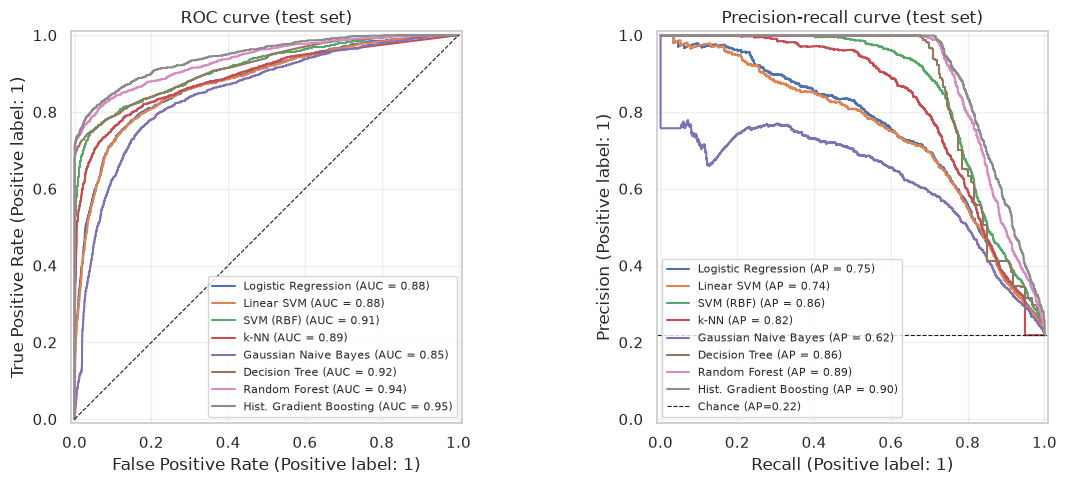

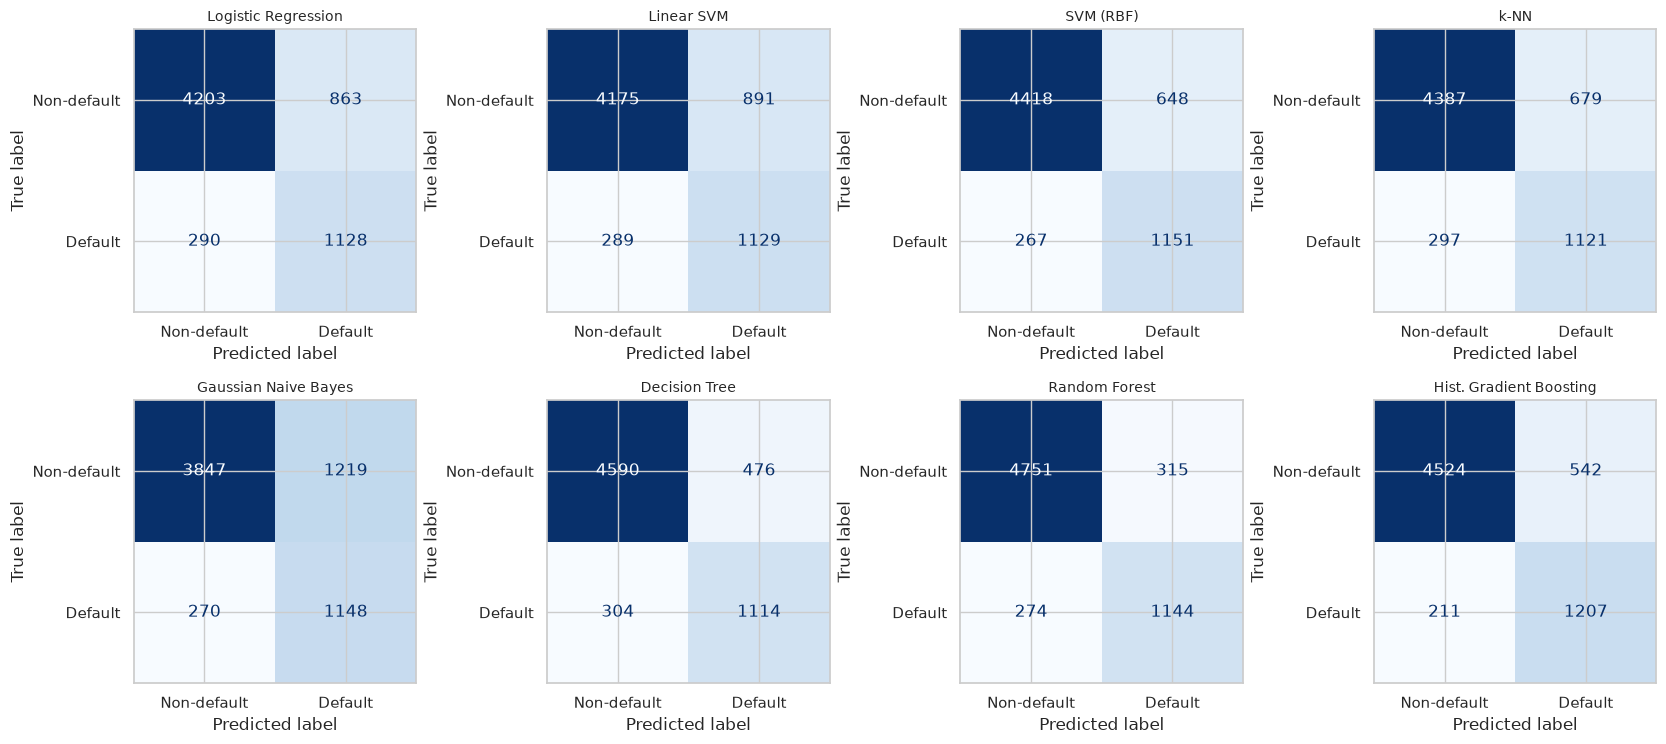

In [26]:
curves = {pipeline.MODEL_LABELS[k]: (y_test, evaluation.scores_of(m, X_test)) for k, m in best.items()}
evaluation.plot_roc_pr(curves, path=config.FIGURES_DIR / "roc_pr_traditional.pdf", title_suffix=" (test set)"); plt.show()
preds = {pipeline.MODEL_LABELS[k]: (y_test, t.predict(X_test)) for k, t in thresholded.items()}
evaluation.plot_confusion_matrices(preds, path=config.FIGURES_DIR / "confusion_traditional.pdf", ncols=4); plt.show()

### 4.3 Is there headroom left?
Several grid optima sit on the edge of their grids, which can mean the search space was too narrow. Two
stronger optimizers test this for the best model family: a 40-candidate random search over seven
gradient-boosting hyper-parameters, and a stacked ensemble of the three strongest tuned families.

In [27]:
headroom, wide_search = experiments.run_headroom(X_train, y_train, searches, n_jobs=N_JOBS, verbose=False)
display(headroom.round(4))
print("best random-search parameters:", {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                                         for k, v in wide_search.best_params_.items()})

,approach,cv_pr_auc,cv_pr_auc_std,time,gain_vs_grid
0,"Hist. Gradient Boosting, grid search (8 candid...",0.8988,0.0026,NaN,0.0000
1,"Hist. Gradient Boosting, random search (40 can...",0.8986,0.0022,158.8906,-0.0003
2,Stacking (Hist. GB + Random Forest + Logistic ...,0.9002,0.0032,181.4861,0.0014


best random-search parameters: {'class_weight': None, 'l2_regularization': np.float64(0.0062), 'learning_rate': np.float64(0.1124), 'max_features': np.float64(0.8951), 'max_iter': 578, 'max_leaf_nodes': 19, 'min_samples_leaf': 45}


Neither the wider search nor stacking improves PR-AUC by more than the fold-to-fold standard deviation. The
tuned gradient-boosting model sits on a plateau, so the remaining error comes from the overlap of the classes in
feature space (section 2), not from under-optimization. The grid-search models are kept.

### 4.4 What drives the predictions? (permutation importance of the best model on the test set)

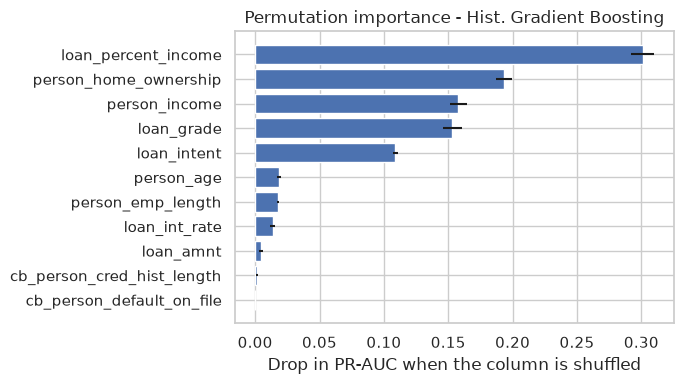

,feature,importance,std
0,loan_percent_income,0.3011,0.0088
1,person_home_ownership,0.1934,0.0062
2,person_income,0.1579,0.0067
3,loan_grade,0.1531,0.0072
4,loan_intent,0.1088,0.0021
5,person_age,0.0186,0.0019
6,person_emp_length,0.0176,0.0010
7,loan_int_rate,0.0136,0.0018
8,loan_amnt,0.0045,0.0016
9,cb_person_cred_hist_length,0.0015,0.0006


In [28]:
best_key = test_results.sort_values("pr_auc", ascending=False).iloc[0]["key"]
imp = experiments.importance_frame(best[best_key], X_test, y_test, n_jobs=N_JOBS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp["feature"][::-1], imp["importance"][::-1], xerr=imp["std"][::-1], color="#4c72b0")
ax.set_xlabel("Drop in PR-AUC when the column is shuffled")
ax.set_title(f"Permutation importance - {pipeline.MODEL_LABELS[best_key]}")
fig.tight_layout(); reporting.save_figure(fig, "importance_best"); plt.show()
imp.round(4)

### 4.5 Error analysis of the best model
Which borrowers does the best model miss (false negatives) at its F2 threshold?

In [29]:
pred_best = thresholded[best_key].predict(X_test)
err = X_test.assign(y=y_test.values, pred=pred_best)
err["outcome"] = np.select([(err.y == 1) & (err.pred == 1), (err.y == 1) & (err.pred == 0), (err.y == 0) & (err.pred == 1)],
                           ["TP", "FN", "FP"], "TN")
error_profile = err.groupby("outcome")[["loan_percent_income", "loan_int_rate", "person_income", "loan_amnt"]].median()
error_profile["count"] = err["outcome"].value_counts()
error_profile["share_grade_A_B"] = err.groupby("outcome")["loan_grade"].apply(lambda s: s.isin(["A", "B"]).mean())
error_profile.round(3)

,loan_percent_income,loan_int_rate,person_income,loan_amnt,count,share_grade_A_B
outcome,,,,,,
FN,0.14,10.74,54000.0,8500.0,211,0.706
FP,0.18,13.47,45600.0,7200.0,542,0.354
TN,0.13,10.00,62000.0,8000.0,4524,0.769
TP,0.27,14.11,39000.0,9600.0,1207,0.332


## 5. Saving the extracted features
The feature matrices produced by the fitted preprocessing steps are saved under `features/` as `.npy`
files and collected in `features/credit_features.h5`. They can be reused without re-running the pipeline.

In [30]:
from creditrisk.pipeline import feature_names, transform_only

saved = {}
for key in ("logreg", best_key):
    pipe = best[key]
    saved[key] = reporting.save_features(
        f"traditional_{key}",
        {"X_train": np.asarray(transform_only(pipe, X_train), dtype=np.float32),
         "X_test": np.asarray(transform_only(pipe, X_test), dtype=np.float32),
         "y_train": y_train.to_numpy(np.int8), "y_test": y_test.to_numpy(np.int8)},
        meta={"feature_names": feature_names(pipe), "config": experiments.PARAM_GRIDS[key][0].as_dict()},
    )
pca_pipe = pipeline.build_pipeline(experiments.PREP_SCALED.with_(pca_variance=0.95)).fit(X_train, y_train)
reporting.save_features("traditional_pca95", {
    "X_train": np.asarray(transform_only(pca_pipe, X_train), dtype=np.float32),
    "X_test": np.asarray(transform_only(pca_pipe, X_test), dtype=np.float32)},
    meta={"explained_variance_ratio": pca_pipe.named_steps["pca"].explained_variance_ratio_.round(5).tolist()})
for p in sorted(config.FEATURES_DIR.rglob("*.npy")):
    print(p.relative_to(ROOT), np.load(p).shape)

features/deep_mlp_embeddings/X_test.npy (6484, 64)
features/deep_mlp_embeddings/X_train.npy (25932, 64)
features/deep_mlp_embeddings/y_test.npy (6484,)
features/deep_mlp_embeddings/y_train.npy (25932,)
features/traditional_hist_gb/X_test.npy (6484, 24)
features/traditional_hist_gb/X_train.npy (25932, 24)
features/traditional_hist_gb/y_test.npy (6484,)
features/traditional_hist_gb/y_train.npy (25932,)
features/traditional_logreg/X_test.npy (6484, 30)
features/traditional_logreg/X_train.npy (25932, 30)
features/traditional_logreg/y_test.npy (6484,)
features/traditional_logreg/y_train.npy (25932,)
features/traditional_pca95/X_test.npy (6484, 14)
features/traditional_pca95/X_train.npy (25932, 14)


## 6. Deep learning pipeline
The deep pipeline learns its representation end to end. Numeric columns are only imputed, clipped and
standardized. Categorical columns become integer codes that feed trainable **entity embeddings**.

* **MLP**: embeddings + numeric features -> [Linear -> BatchNorm -> ReLU -> Dropout] x L -> logit,
  trained with AdamW and a class-weighted BCE loss. Early stopping uses the validation PR-AUC.
* **TabNet** (Arik & Pfister, 2021): sequential attention that selects the features to use at each decision step.

Each network is trained with five seeds (`deep.SEEDS`, derived from `config.SEED`) and reported as
**mean ± standard deviation** over them. Training is deterministic for a given seed on one machine, but
different CPUs and PyTorch builds round slightly differently, which can move the epoch at which early stopping
halts; the spread over seeds shows how much of a single run's score is that kind of noise.

### 6.1 MLP architecture and training variants

In [31]:
torch.set_num_threads(CORES)
mlp_results, mlp_runs, mlp_models = deep.run_mlp_variants(X_train, y_train, X_test, y_test)
display(deep.format_mean_std(mlp_results, ["val_pr_auc", "pr_auc", "roc_auc", "f2_tuned", "recall_tuned", "precision_tuned"])
        .assign(epochs=mlp_results.epochs.round(1), fit_time=mlp_results.fit_time.round(1)))

[MLP] MLP 128-64 (reference)           val PR-AUC=0.8640±0.0082 test PR-AUC=0.8619±0.0017 (7s, 56 epochs per seed)


[MLP] MLP 64-32 (smaller)              val PR-AUC=0.8638±0.0077 test PR-AUC=0.8623±0.0017 (6s, 66 epochs per seed)


[MLP] MLP 256-128-64 (deeper)          val PR-AUC=0.8664±0.0069 test PR-AUC=0.8650±0.0019 (10s, 44 epochs per seed)


[MLP] No dropout                       val PR-AUC=0.8596±0.0078 test PR-AUC=0.8582±0.0022 (3s, 35 epochs per seed)


[MLP] One-hot instead of embeddings    val PR-AUC=0.8624±0.0072 test PR-AUC=0.8609±0.0032 (5s, 48 epochs per seed)


[MLP] No class weighting               val PR-AUC=0.8645±0.0063 test PR-AUC=0.8623±0.0020 (6s, 51 epochs per seed)


[MLP] No engineered features           val PR-AUC=0.8618±0.0059 test PR-AUC=0.8604±0.0004 (7s, 55 epochs per seed)


,model,val_pr_auc,pr_auc,roc_auc,f2_tuned,recall_tuned,precision_tuned,epochs,fit_time
0,MLP 128-64 (reference),0.8640 ± 0.0082,0.8619 ± 0.0017,0.9200 ± 0.0017,0.7621 ± 0.0017,0.7956 ± 0.0088,0.6535 ± 0.0283,55.6,6.8
1,MLP 64-32 (smaller),0.8638 ± 0.0077,0.8623 ± 0.0017,0.9208 ± 0.0014,0.7619 ± 0.0003,0.8017 ± 0.0177,0.6392 ± 0.0485,65.8,5.6
2,MLP 256-128-64 (deeper),0.8664 ± 0.0069,0.8650 ± 0.0019,0.9213 ± 0.0015,0.7644 ± 0.0035,0.7949 ± 0.0117,0.6647 ± 0.0352,44.0,9.9
3,No dropout,0.8596 ± 0.0078,0.8582 ± 0.0022,0.9183 ± 0.0022,0.7624 ± 0.0027,0.7946 ± 0.0116,0.6575 ± 0.0324,34.6,2.6
4,One-hot instead of embeddings,0.8624 ± 0.0072,0.8609 ± 0.0032,0.9196 ± 0.0014,0.7609 ± 0.0031,0.7946 ± 0.0155,0.6543 ± 0.0499,47.6,5.0
5,No class weighting,0.8645 ± 0.0063,0.8623 ± 0.0020,0.9191 ± 0.0015,0.7583 ± 0.0037,0.7982 ± 0.0204,0.6366 ± 0.0515,50.6,6.0
6,No engineered features,0.8618 ± 0.0059,0.8604 ± 0.0004,0.9191 ± 0.0005,0.7578 ± 0.0048,0.8117 ± 0.0300,0.6085 ± 0.0769,55.2,6.5


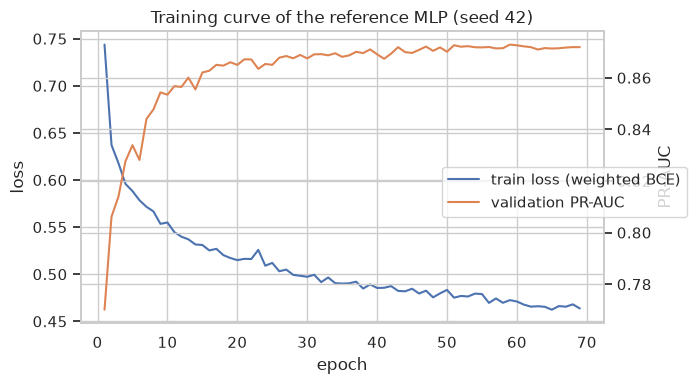

In [32]:
ref_mlp = mlp_models["MLP 128-64 (reference)"]
hist = pd.DataFrame(ref_mlp.history_)
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(hist.epoch, hist.train_loss, label="train loss (weighted BCE)", color="#4c72b0")
ax2 = ax1.twinx(); ax2.plot(hist.epoch, hist.val_pr_auc, label="validation PR-AUC", color="#dd8452")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax2.set_ylabel("PR-AUC")
fig.legend(loc="center right"); ax1.set_title(f"Training curve of the reference MLP (seed {config.SEED})")
fig.tight_layout(); reporting.save_figure(fig, "mlp_training"); plt.show()

### 6.2 TabNet


Early stopping occurred at epoch 44 with best_epoch = 34 and best_val_0_auc = 0.92467


[TabNet] seed 42  test PR-AUC=0.8638 (30s, 45 epochs)



Early stopping occurred at epoch 43 with best_epoch = 33 and best_val_0_auc = 0.91464


[TabNet] seed 43  test PR-AUC=0.8581 (29s, 44 epochs)



Early stopping occurred at epoch 58 with best_epoch = 48 and best_val_0_auc = 0.92431


[TabNet] seed 44  test PR-AUC=0.8640 (43s, 59 epochs)



Early stopping occurred at epoch 39 with best_epoch = 29 and best_val_0_auc = 0.90987


[TabNet] seed 45  test PR-AUC=0.8595 (27s, 40 epochs)


Stop training because you reached max_epochs = 60 with best_epoch = 56 and best_val_0_auc = 0.92821


[TabNet] seed 46  test PR-AUC=0.8604 (41s, 60 epochs)


,model,pr_auc,roc_auc,f2_tuned,recall_tuned,precision_tuned,epochs,fit_time
0,TabNet,0.8612 ± 0.0026,0.9180 ± 0.0014,0.7568 ± 0.0039,0.7984 ± 0.0170,0.6288 ± 0.0398,49.6,34.0


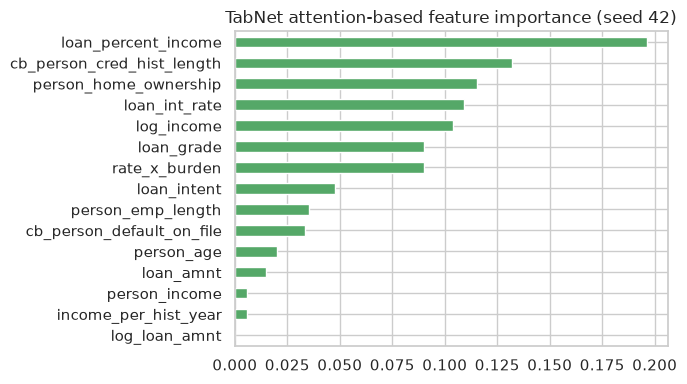

In [33]:
tabnet_results, tabnet_runs, tabnet = deep.run_tabnet(X_train, y_train, X_test, y_test)
display(deep.format_mean_std(tabnet_results, ["pr_auc", "roc_auc", "f2_tuned", "recall_tuned", "precision_tuned"])
        .assign(epochs=tabnet_results.epochs.round(1), fit_time=tabnet_results.fit_time.round(1)))
fig, ax = plt.subplots(figsize=(7, 4))
tabnet.feature_importances().sort_values().plot.barh(ax=ax, color="#55a868")
ax.set_title(f"TabNet attention-based feature importance (seed {config.SEED})"); fig.tight_layout()
reporting.save_figure(fig, "tabnet_importance"); plt.show()

### 6.3 Learned embeddings as features
The 64-dimensional penultimate layer of the reference MLP (seed 42) is saved as a feature set. A plain logistic
regression trained on it shows how much of the network's power lies in the learned representation.

In [34]:
from sklearn.linear_model import LogisticRegression
emb_train, emb_test = ref_mlp.embed(X_train), ref_mlp.embed(X_test)
reporting.save_features("deep_mlp_embeddings", {"X_train": emb_train.astype(np.float32), "X_test": emb_test.astype(np.float32),
                                                "y_train": y_train.to_numpy(np.int8), "y_test": y_test.to_numpy(np.int8)},
                        meta={"source": "penultimate layer of MLP 128-64 (reference)"})
lr_emb = LogisticRegression(max_iter=2000, class_weight="balanced").fit(emb_train, y_train)
p = lr_emb.predict_proba(emb_test)[:, 1]
emb_row = {"model": "LogReg on MLP embeddings", **evaluation.compute_metrics(y_test, (p >= 0.5).astype(int), p)}
display(pd.DataFrame([emb_row]).round(4))

,model,accuracy,balanced_accuracy,precision,recall,f1,f2,roc_auc,pr_auc
0,LogReg on MLP embeddings,0.8814,0.8431,0.7095,0.775,0.7408,0.761,0.9209,0.8629


### 6.4 Traditional vs deep learning on the test set

,model,pr_auc,roc_auc,f2_tuned,recall_tuned,precision_tuned,accuracy_tuned
0,MLP 128-64 (reference),0.8619 ± 0.0017,0.9200 ± 0.0017,0.7621 ± 0.0017,0.7956 ± 0.0088,0.6535 ± 0.0283,0.8626 ± 0.0105
1,TabNet,0.8612 ± 0.0026,0.9180 ± 0.0014,0.7568 ± 0.0039,0.7984 ± 0.0170,0.6288 ± 0.0398,0.8517 ± 0.0148


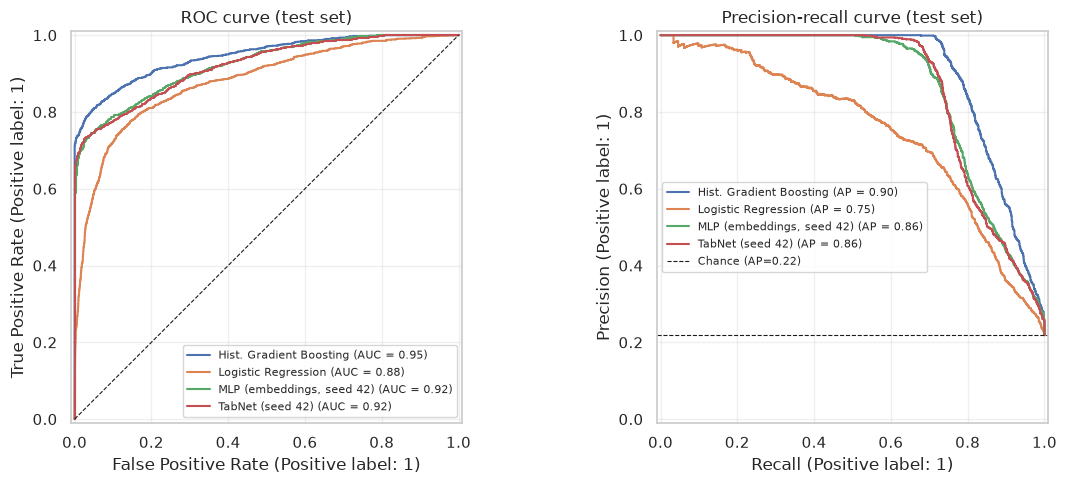

In [35]:
dl_table = pd.concat([mlp_results[mlp_results.model == "MLP 128-64 (reference)"], tabnet_results], ignore_index=True)
dl_table.to_csv(config.RESULTS_DIR / "test_deep.csv", index=False)
display(deep.format_mean_std(dl_table, ["pr_auc", "roc_auc", "f2_tuned", "recall_tuned", "precision_tuned", "accuracy_tuned"]))
# Curves need one model each, so the networks are drawn for the first seed.
curves_dl = {
    pipeline.MODEL_LABELS[best_key]: (y_test, evaluation.scores_of(best[best_key], X_test)),
    "Logistic Regression": (y_test, evaluation.scores_of(best["logreg"], X_test)),
    f"MLP (embeddings, seed {config.SEED})": (y_test, ref_mlp.predict_proba(X_test)[:, 1]),
    f"TabNet (seed {config.SEED})": (y_test, tabnet.predict_proba(X_test)[:, 1]),
}
evaluation.plot_roc_pr(curves_dl, path=config.FIGURES_DIR / "roc_pr_traditional_vs_deep.pdf", title_suffix=" (test set)"); plt.show()

## 7. Extension: Bayesian network (Talented Engineering program)
Implemented from scratch in `modules/creditrisk/bayesnet/`:

* `graph.py`: DAG with cycle checks, Kahn topological sort and Markov blankets.
* `network.py`: CPTs estimated by MAP with a Dirichlet prior (Laplace smoothing), computed per family on the rows
  where that family is fully observed (missing values need no imputation), plus ancestral sampling.
* `structure.py`: Naive Bayes, TAN (Chow-Liu tree on conditional mutual information), greedy hill climbing on BIC,
  and an expert-designed DAG.
* `inference.py`: **exact** inference by variable elimination (barren-node pruning, min-weight elimination order),
  checked against brute-force enumeration in the unit tests. **Approximate** inference by rejection sampling,
  likelihood weighting and Gibbs sampling.

Numeric features are discretized into quantile bins learned on the training split.

### 7.1 Discretization granularity and smoothing, chosen per structure on a validation split of the training set

In [36]:
bn_sens = bnx.run_sensitivity(X_train, y_train)
sens_table = bn_sens.pivot_table(index=["n_bins", "alpha"], columns="structure", values="pr_auc")
display(sens_table.round(4))
# Each structure gets the (bins, alpha) that maximizes its own validation PR-AUC.
BN_SETTINGS = bnx.select_settings(bn_sens)
print("Selected (n_bins, alpha) per structure:", BN_SETTINGS)

structure     Expert DAG  Hill-climb BIC  Naive Bayes     TAN
n_bins alpha                                                 
3      0.1        0.7024          0.6088       0.6251  0.7401
       1.0        0.7015          0.6111       0.6249  0.7393
       10.0       0.6912          0.6114       0.6261  0.7312
5      0.1        0.7338          0.6479       0.6633  0.7672
       1.0        0.7316          0.6479       0.6649  0.7656
       10.0       0.7111          0.6457       0.6645  0.7578
8      0.1        0.7948          0.6859       0.6905  0.7915
       1.0        0.7908          0.6879       0.6919  0.7893
       10.0       0.7674          0.6871       0.6916  0.7787
12     0.1        0.7940          0.7416       0.6940  0.7542
       1.0        0.7915          0.7416       0.6956  0.7515
       10.0       0.7780          0.7383       0.6954  0.7403

Selected (n_bins, alpha) per structure: {'Expert DAG': (8, 0.1), 'Hill-climb BIC': (12, 0.1), 'Naive Bayes': (12, 1.0), 'TAN': (8, 0.1)}


### 7.2 Structures and classification performance on the test set

In [37]:
bn_results, bn_models = bnx.run_classification(X_train, y_train, X_test, y_test, settings=BN_SETTINGS)
display(bn_results[["structure", "n_bins", "alpha", "edges", "parameters", "test_loglik", "pr_auc", "roc_auc", "threshold", "f2_tuned", "recall_tuned", "precision_tuned", "inference_time"]].round(4))

[BN] Expert DAG      bins= 8 alpha=0.1  edges=12 params= 2041 PR-AUC=0.7822 F2(tuned)=0.7152 (0.3s)


[BN] Hill-climb BIC  bins=12 alpha=0.1  edges=17 params= 3736 PR-AUC=0.7332 F2(tuned)=0.7033 (0.4s)


[BN] Naive Bayes     bins=12 alpha=1    edges=11 params=  171 PR-AUC=0.7061 F2(tuned)=0.7149 (0.4s)


[BN] TAN             bins= 8 alpha=0.1  edges=21 params=  777 PR-AUC=0.7895 F2(tuned)=0.7390 (0.4s)


,structure,n_bins,alpha,edges,parameters,test_loglik,pr_auc,roc_auc,threshold,f2_tuned,recall_tuned,precision_tuned,inference_time
0,Expert DAG,8,0.1,12,2041,-100749.8607,0.7822,0.8712,0.16,0.7152,0.7736,0.5493,0.3045
1,Hill-climb BIC,12,0.1,17,3736,-103692.2121,0.7332,0.8579,0.18,0.7033,0.7941,0.4826,0.3799
2,Naive Bayes,12,1.0,11,171,-136945.6389,0.7061,0.8635,0.20,0.7149,0.7962,0.5076,0.3766
3,TAN,8,0.1,21,777,-105532.0568,0.7895,0.8900,0.18,0.7390,0.8110,0.5453,0.3523


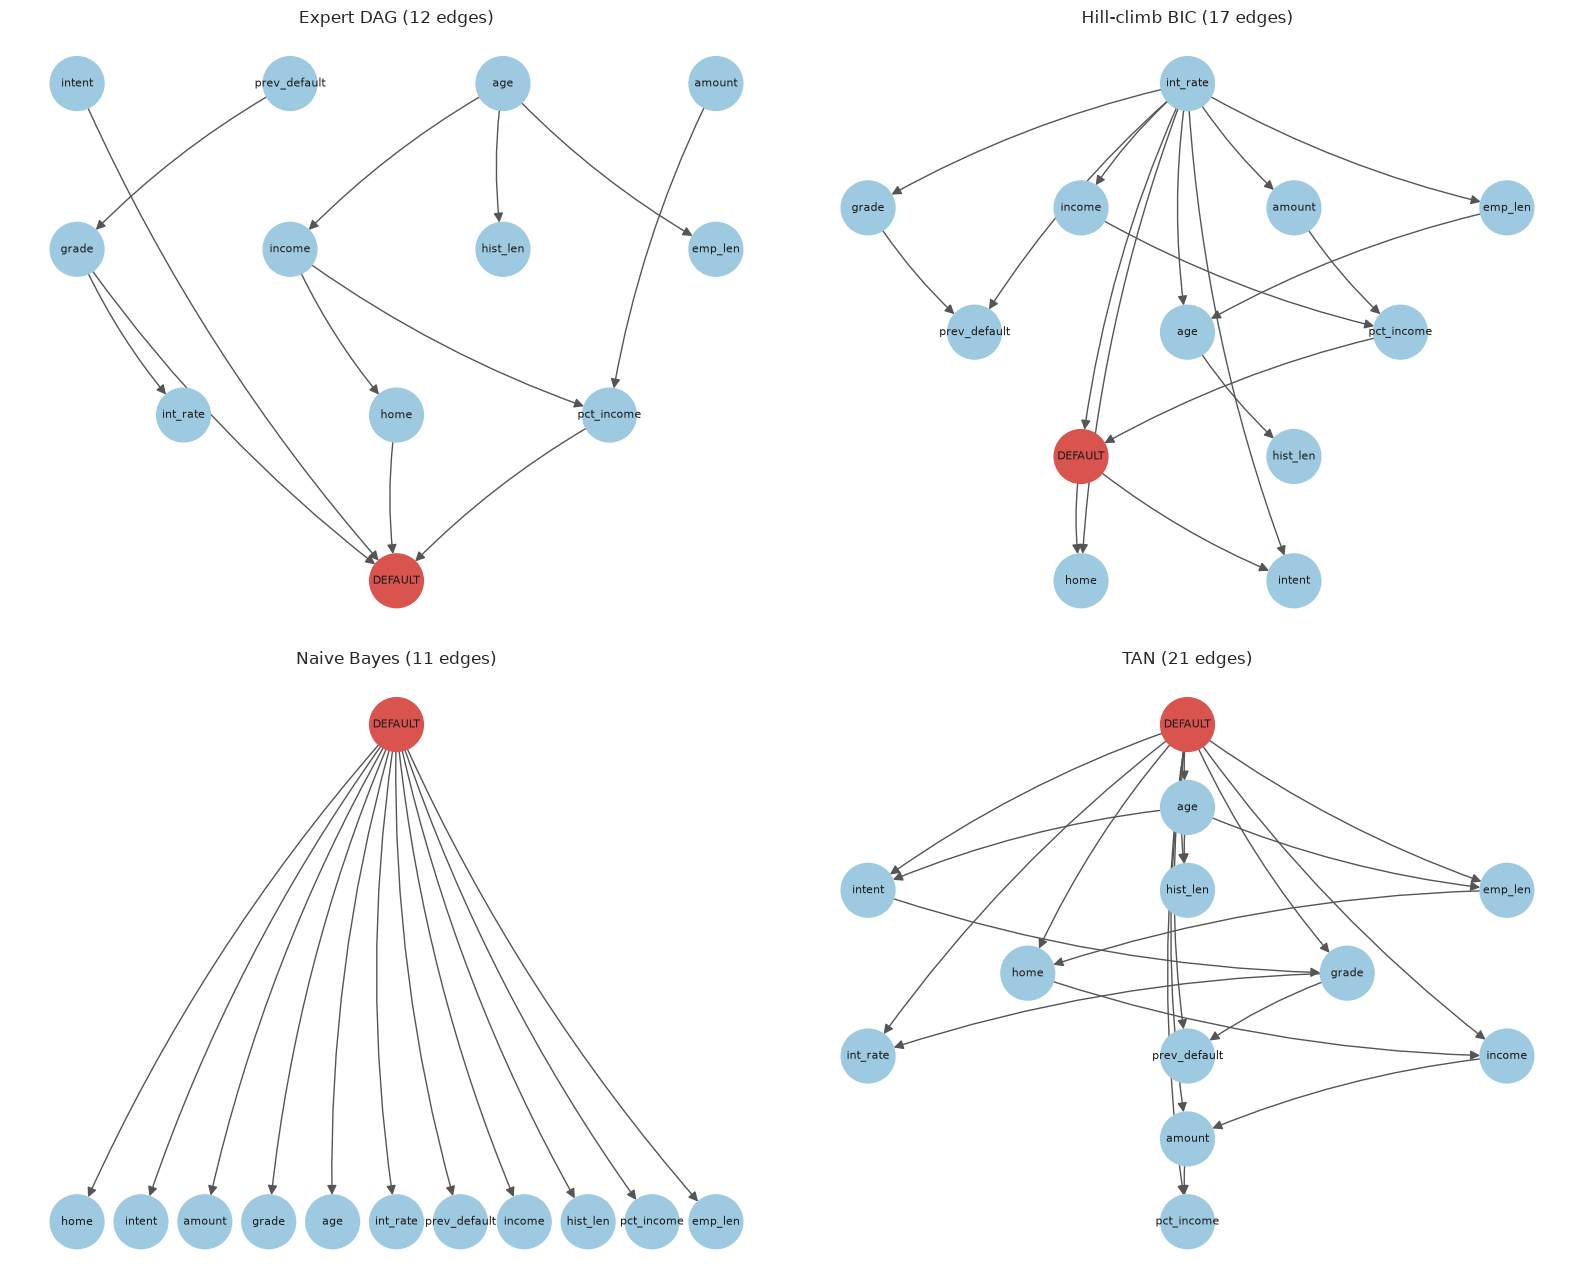

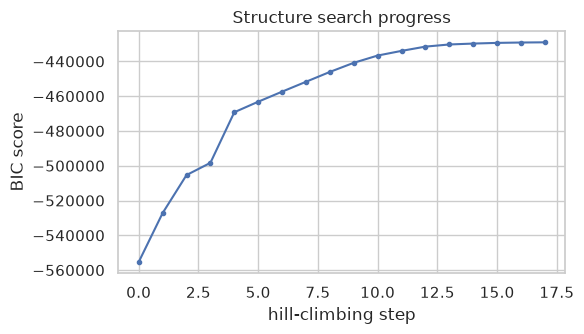

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, (name, m) in zip(axes.flat, bn_models.items()):
    bnx.draw_dag(m["bn"].dag, f"{name} ({len(m['bn'].dag.edges)} edges)", ax=ax)
fig.tight_layout(); reporting.save_figure(fig, "bn_structures"); plt.show()
trace = bn_models["Hill-climb BIC"]["trace"]
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(trace, marker="o", ms=3)
ax.set_xlabel("hill-climbing step"); ax.set_ylabel("BIC score"); ax.set_title("Structure search progress")
fig.tight_layout(); reporting.save_figure(fig, "bn_bic_trace"); plt.show()

### 7.3 Reasoning with the networks (exact queries by variable elimination)
Predictive queries (cause to effect) and diagnostic queries (effect to cause), answered exactly. The empirical
column gives the conditional frequency in the training data. A network whose answers drift from it makes an
independence assumption that the data contradict.

In [39]:
bn_best_name = bn_results.sort_values("pr_auc", ascending=False).iloc[0]["structure"]
print("Best BN classifier:", bn_best_name)
# Compare exact answers of the best (TAN) and the expert network with the empirical frequencies.
queries = bnx.example_queries({name: (bn_models[name]["bn"], bn_models[name]["disc"].states_) for name in ("TAN", "Expert DAG")},
                              X_train, y_train)
queries.to_csv(config.RESULTS_DIR / "bn_queries.csv", index=False)
queries.round(4)

Best BN classifier: TAN


,query,empirical,support,TAN,Expert DAG
0,P(default),0.2187,25932,0.2187,0.2594
1,P(default | grade=A),0.0998,8584,0.0998,0.1750
2,P(default | grade=D),0.5902,2889,0.5900,0.5749
3,P(default | grade=G),0.9792,48,0.9675,0.6361
4,P(default | home=RENT),0.3167,13114,0.3149,0.3675
5,P(default | home=OWN),0.0715,2042,0.0681,0.1696
6,"P(default | grade=D, home=OWN)",0.0463,216,0.2731,0.0780
7,P(default | intent=MEDICAL),0.2672,4842,0.2672,0.3008
8,P(default | intent=VENTURE),0.1505,4610,0.1506,0.1901
9,P(prev_default=Y | default=1),0.3063,5671,0.3064,0.2685


### 7.4 Exact vs approximate inference
For random test borrowers we condition on 2, 5 or 10 of their observed features and compare the sampled
estimate of P(default | e) with the exact value from variable elimination.

,evidence_size,method,samples,mae,max_error,time_per_query,acceptance_rate
0,2,Variable elimination,0,0.0000,0.0000,0.0001,NaN
1,2,Rejection sampling,100,0.1636,0.8606,0.0002,0.0490
2,2,Likelihood weighting,100,0.0467,0.3337,0.0002,NaN
3,2,Gibbs sampling,100,0.0444,0.1759,0.0581,NaN
4,2,Rejection sampling,1000,0.0639,0.2568,0.0008,0.0450
5,2,Likelihood weighting,1000,0.0160,0.0723,0.0008,NaN
6,2,Gibbs sampling,1000,0.0154,0.0722,0.0848,NaN
7,2,Rejection sampling,10000,0.0178,0.0649,0.0074,0.0468
8,2,Likelihood weighting,10000,0.0049,0.0257,0.0066,NaN
9,2,Gibbs sampling,10000,0.0061,0.0241,0.3276,NaN


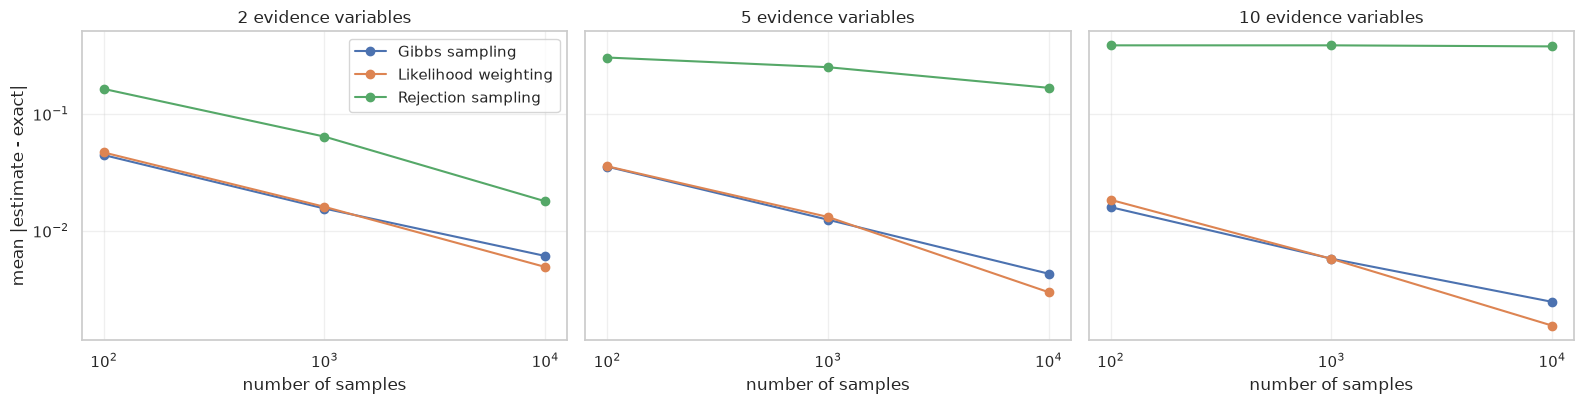

In [40]:
tan = bn_models["TAN"]
inf = bnx.run_inference_comparison(tan["bn"], tan["disc"].transform(X_test), verbose=False)
display(inf.round(4))
approx = inf[inf.method != "Variable elimination"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (k, grp) in zip(axes, approx.groupby("evidence_size")):
    for method, g in grp.groupby("method"):
        ax.plot(g.samples, g.mae, marker="o", label=method)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"{k} evidence variables")
    ax.set_xlabel("number of samples"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mean |estimate - exact|"); axes[0].legend()
fig.tight_layout(); reporting.save_figure(fig, "bn_inference_error"); plt.show()

## 8. Overall comparison (test set, 6,484 loans)
The deep models are the mean over their five seeds, with the standard deviation in the `_std` columns and as
error bars.

,family,model,pr_auc,roc_auc,f2,recall,precision,accuracy,pr_auc_std,roc_auc_std,f2_std,recall_std,precision_std,accuracy_std
0,Traditional,Hist. Gradient Boosting,0.9045,0.9459,0.8132,0.8512,0.6901,0.8839,NaN,NaN,NaN,NaN,NaN,NaN
1,Traditional,Random Forest,0.8934,0.9361,0.8021,0.8068,0.7841,0.9092,NaN,NaN,NaN,NaN,NaN,NaN
2,Traditional,Decision Tree,0.8623,0.9180,0.7670,0.7856,0.7006,0.8797,NaN,NaN,NaN,NaN,NaN,NaN
3,Deep learning,MLP (entity embeddings),0.8619,0.9200,0.7621,0.7956,0.6535,0.8626,0.0017,0.0017,0.0017,0.0088,0.0283,0.0105
4,Deep learning,TabNet,0.8612,0.9180,0.7568,0.7984,0.6288,0.8517,0.0026,0.0014,0.0039,0.0170,0.0398,0.0148
5,Traditional,SVM (RBF),0.8561,0.9147,0.7703,0.8117,0.6398,0.8589,NaN,NaN,NaN,NaN,NaN,NaN
6,Traditional,k-NN,0.8163,0.8925,0.7501,0.7906,0.6228,0.8495,NaN,NaN,NaN,NaN,NaN,NaN
7,Bayesian network,BN - TAN,0.7895,0.8900,0.7390,0.8110,0.5453,0.8108,NaN,NaN,NaN,NaN,NaN,NaN
8,Bayesian network,BN - Expert DAG,0.7822,0.8712,0.7152,0.7736,0.5493,0.8117,NaN,NaN,NaN,NaN,NaN,NaN
9,Traditional,Logistic Regression,0.7512,0.8797,0.7360,0.7955,0.5665,0.8222,NaN,NaN,NaN,NaN,NaN,NaN


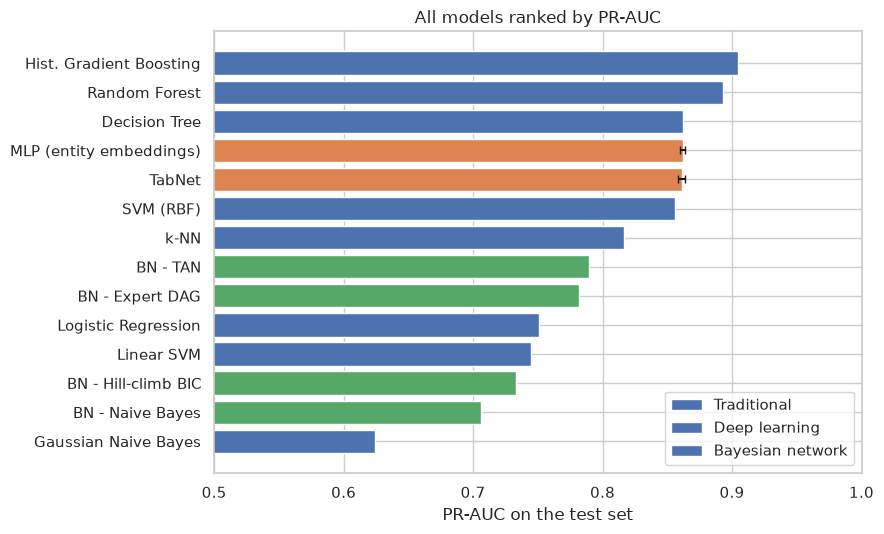

In [41]:
OVERALL_METRICS = {"pr_auc": "pr_auc", "roc_auc": "roc_auc", "f2": "f2_tuned", "recall": "recall_tuned",
                   "precision": "precision_tuned", "accuracy": "accuracy_tuned"}

def pick(df, name_col, name, family, label=None):
    r = df[df[name_col] == name].iloc[0]
    row = {"family": family, "model": label or name, **{k: r[c] for k, c in OVERALL_METRICS.items()}}
    # Only the seed-averaged deep models carry a spread.
    return row | {f"{k}_std": r.get(f"{c}_std", np.nan) for k, c in OVERALL_METRICS.items()}

overall = pd.DataFrame(
    [pick(test_results, "key", k, "Traditional", pipeline.MODEL_LABELS[k]) for k in best]
    + [pick(mlp_results, "model", "MLP 128-64 (reference)", "Deep learning", "MLP (entity embeddings)"),
       pick(tabnet_results, "model", "TabNet", "Deep learning")]
    + [pick(bn_results, "structure", s, "Bayesian network", f"BN - {s}") for s in bn_results.structure]
).sort_values("pr_auc", ascending=False).reset_index(drop=True)
overall.to_csv(config.RESULTS_DIR / "overall.csv", index=False)
display(overall.round(4))
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = overall.family.map({"Traditional": "#4c72b0", "Deep learning": "#dd8452", "Bayesian network": "#55a868"})
ax.barh(overall.model[::-1], overall.pr_auc[::-1], xerr=overall.pr_auc_std[::-1], color=colors[::-1], capsize=3)
for fam, c in [("Traditional", "#4c72b0"), ("Deep learning", "#dd8452"), ("Bayesian network", "#55a868")]:
    ax.barh([], [], color=c, label=fam)
ax.set_xlim(0.5, 1); ax.set_xlabel("PR-AUC on the test set"); ax.legend(loc="lower right")
ax.set_title("All models ranked by PR-AUC")
fig.tight_layout(); reporting.save_figure(fig, "overall_pr_auc"); plt.show()

## 9. Conclusions
* **Gradient-boosted trees win.** Tree ensembles capture the strong interactions between grade, loan-to-income
  ratio and home ownership. Linear models cannot represent them without hand-crafted features.
* **Preprocessing matters most for the scale-sensitive models.** Scaling, clipping and the encoding choice
  change k-NN, SVM and logistic regression substantially, while trees are almost unaffected. PCA never helps
  on this low-dimensional data.
* **Deep learning is competitive but does not beat boosting** on 26k rows of tabular data, in line with the
  literature (Grinsztajn et al., 2022). The entity-embedding MLP beats every linear model.
* **Bayesian networks** give interpretable, probabilistic reasoning, including diagnostic queries and native
  handling of missing features. They lose some accuracy to discretization. TAN, which learns its structure
  for predicting the class, is the best network classifier. Likelihood weighting and Gibbs sampling scale with
  evidence, while rejection sampling collapses when many variables are observed.

In [42]:
print(f"Total runtime: {(time.perf_counter() - T_START) / 60:.1f} minutes")

Total runtime: 34.4 minutes
